In [1]:
# AdaBoost Classifier
# Train multiple weak learners sequentially and combine their predictions.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create weak learner
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Create AdaBoost model
model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Estimators: 5, Accuracy: 0.9333
Estimators: 10, Accuracy: 0.9333
Estimators: 20, Accuracy: 0.9000
Estimators: 50, Accuracy: 0.9333
Estimators: 100, Accuracy: 0.9333
Estimators: 200, Accuracy: 0.9333


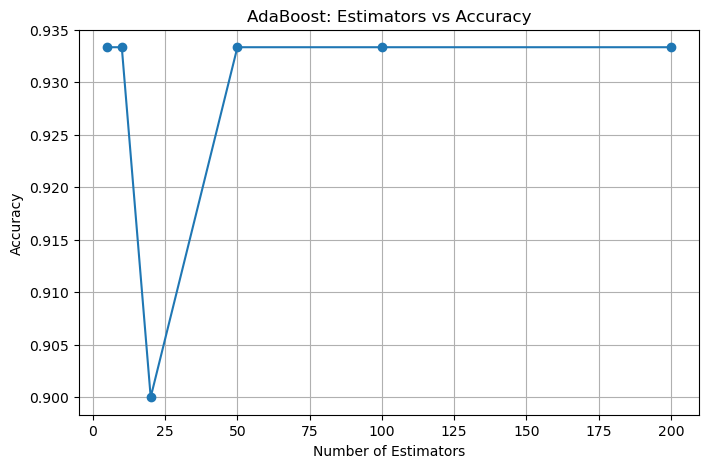

In [2]:
# AdaBoost: Effect of n_estimators
# Compare classification accuracy with different numbers of weak learners.

tree_values = [5, 10, 20, 50, 100, 200]

results = []

for n in tree_values:

    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=n,
        learning_rate=1.0,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Estimators: {n}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(tree_values, results, marker="o")

plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Estimators vs Accuracy")
plt.grid(True)

plt.show()

Learning Rate: 0.01, Accuracy: 0.9333
Learning Rate: 0.05, Accuracy: 0.9333
Learning Rate: 0.1, Accuracy: 0.9667
Learning Rate: 0.5, Accuracy: 0.9667
Learning Rate: 1.0, Accuracy: 0.9333
Learning Rate: 1.5, Accuracy: 0.9333


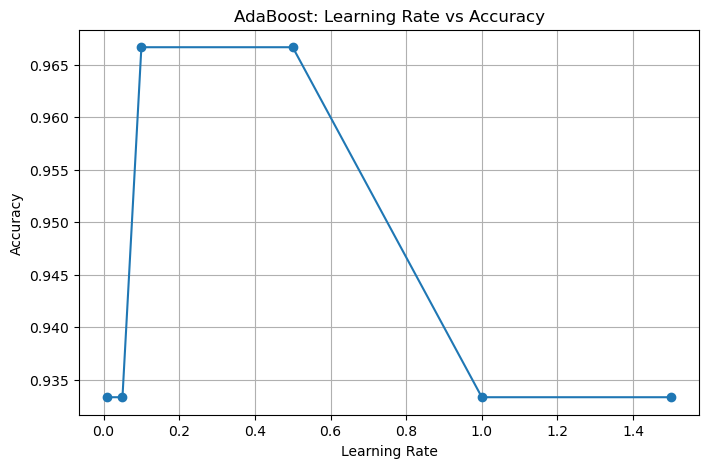

In [3]:
# AdaBoost: Effect of learning_rate
# Compare different learning rates while keeping the number of estimators fixed.

learning_rates = [0.01, 0.05, 0.1, 0.5, 1.0, 1.5]

results = []

for rate in learning_rates:

    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=rate,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append(accuracy)

    print(f"Learning Rate: {rate}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(learning_rates, results, marker="o")

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Learning Rate vs Accuracy")
plt.grid(True)

plt.show()

Tree Depth: 1, Accuracy: 0.9333
Tree Depth: 2, Accuracy: 0.9667
Tree Depth: 3, Accuracy: 0.9667
Tree Depth: 4, Accuracy: 0.9333
Tree Depth: 5, Accuracy: 0.9333


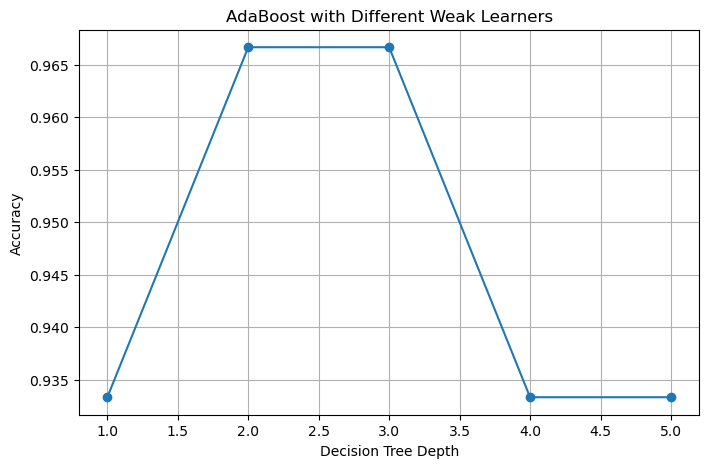

In [4]:
# AdaBoost with Different Weak Learners
# Compare shallow decision trees as base estimators.

depths = [1, 2, 3, 4, 5]

results = []

for depth in depths:

    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    )

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    results.append(accuracy)

    print(f"Tree Depth: {depth}, Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(depths, results, marker="o")

plt.xlabel("Decision Tree Depth")
plt.ylabel("Accuracy")
plt.title("AdaBoost with Different Weak Learners")
plt.grid(True)

plt.show()

### AdaBoost code from scratch

In [5]:
# AdaBoost From Scratch
# Implement weak learner training, weighted error, alpha, sample weight updates, and weighted voting.

import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


class AdaBoostScratch:

    def __init__(self, n_estimators=10, max_depth=1):

        self.n_estimators = n_estimators
        self.max_depth = max_depth

        self.models = []
        self.alphas = []

    # Train AdaBoost
    def fit(self, X, y):

        n_samples = X.shape[0]

        # Convert labels into -1 and +1
        y = np.where(y == 0, -1, 1)

        # Initialize equal sample weights
        sample_weights = np.ones(n_samples) / n_samples

        for i in range(self.n_estimators):

            # Create weak learner
            model = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=42 + i
            )

            # Train using sample weights
            model.fit(
                X,
                y,
                sample_weight=sample_weights
            )

            # Predict training samples
            predictions = model.predict(X)

            # Calculate weighted error
            incorrect = predictions != y

            error = np.sum(
                sample_weights * incorrect
            )

            # Avoid division by zero
            error = np.clip(error, 1e-10, 1 - 1e-10)

            # Calculate alpha
            alpha = 0.5 * np.log(
                (1 - error) / error
            )

            # Update sample weights
            sample_weights *= np.exp(
                -alpha * y * predictions
            )

            # Normalize sample weights
            sample_weights /= np.sum(sample_weights)

            # Save weak learner and alpha
            self.models.append(model)
            self.alphas.append(alpha)

            print(f"Iteration: {i + 1}")
            print(f"Weighted Error: {error:.4f}")
            print(f"Alpha: {alpha:.4f}")
            print(f"Sample Weights: {np.round(sample_weights, 4)}")
            print("-" * 50)

            # Stop if perfect classification
            if error <= 1e-10:
                break

    # Make predictions
    def predict(self, X):

        predictions = np.zeros(X.shape[0])

        for model, alpha in zip(self.models, self.alphas):

            pred = model.predict(X)

            predictions += alpha * pred

        return np.where(predictions >= 0, 1, -1)


# Generate dataset
X, y = make_classification(
    n_samples=500,
    n_features=5,
    n_informative=3,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create model
model = AdaBoostScratch(
    n_estimators=10,
    max_depth=1
)

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
y_test_encoded = np.where(y_test == 0, -1, 1)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred))

print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred))

Iteration: 1
Weighted Error: 0.1275
Alpha: 0.9616
Sample Weights: [0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0098 0.0098
 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014 0.0014 0.0098 0.0014 0.0014
 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0098 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0098 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0098 0.0014
 0.0014 0.0014 0.0098 0.0098 0.0014 0.0014 0.0098 0.0098 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0098 0.0014 0.0098 0.0098 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0098 0.0014 0.0014
 0.0098 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014 0.0014
 0.0014 0.0

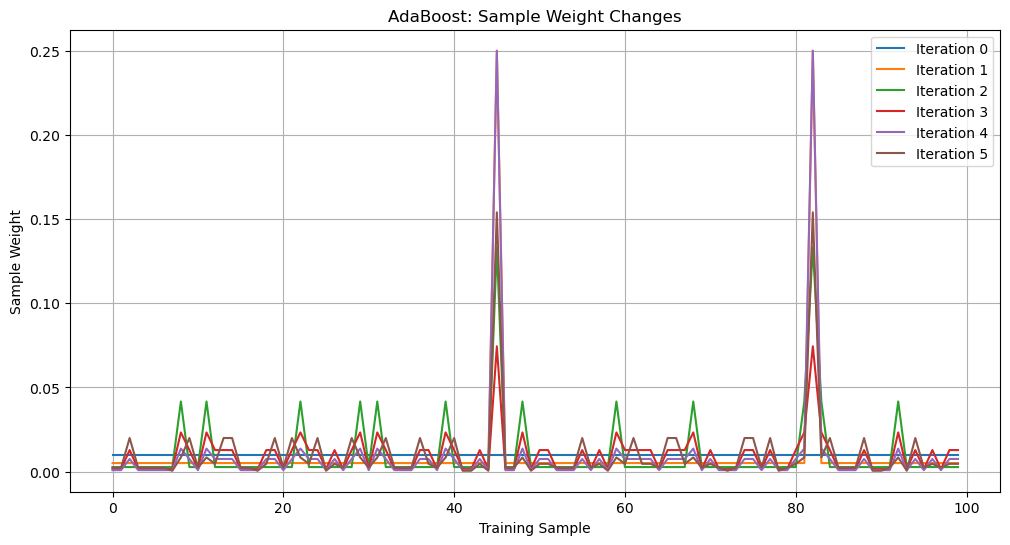

In [6]:
# AdaBoost Sample Weight Visualization
# Track how sample weights change after each boosting iteration.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=42
)

y = np.where(y == 0, -1, 1)

n_samples = len(y)

weights = np.ones(n_samples) / n_samples

n_estimators = 5

weight_history = [weights.copy()]

for i in range(n_estimators):

    model = DecisionTreeClassifier(
        max_depth=1,
        random_state=42 + i
    )

    model.fit(X, y, sample_weight=weights)

    predictions = model.predict(X)

    error = np.sum(
        weights * (predictions != y)
    )

    error = np.clip(error, 1e-10, 1 - 1e-10)

    alpha = 0.5 * np.log((1 - error) / error)

    weights *= np.exp(-alpha * y * predictions)

    weights /= weights.sum()

    weight_history.append(weights.copy())


# Plot weight changes
weight_history = np.array(weight_history)

plt.figure(figsize=(12, 6))

for i in range(n_estimators + 1):

    plt.plot(
        weight_history[i],
        label=f"Iteration {i}"
    )

plt.xlabel("Training Sample")
plt.ylabel("Sample Weight")
plt.title("AdaBoost: Sample Weight Changes")

plt.legend()
plt.grid(True)
plt.show()

Iteration: 1
Weighted Error: 0.1708
Alpha: 0.7899
Sample Weights: [0.0025 0.0122 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0122 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025
 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0122 0.0122 0.0122 0.0122 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025
 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0122
 0.0025 0.0025 0.0025 0.0025 0.0122 0.0122 0.0025 0.0025 0.0025 0.0122
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0122 0.0122 0.0025
 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0122 0.0

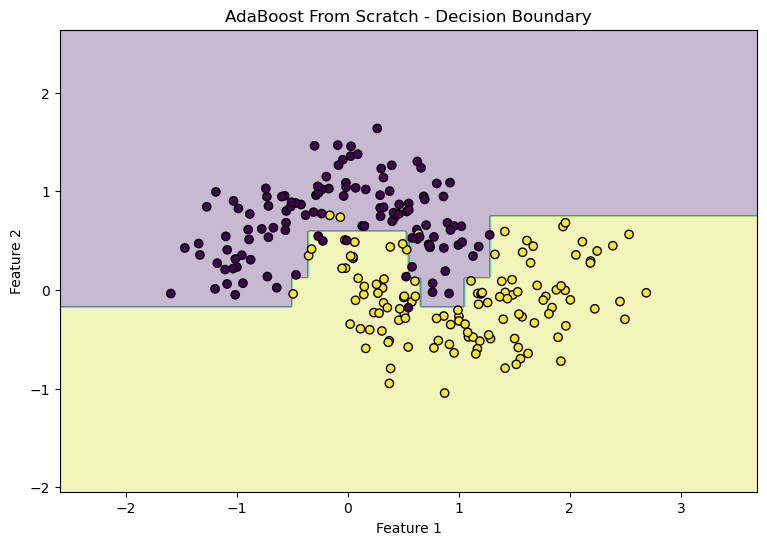

In [7]:
# AdaBoost Decision Boundary
# Visualize the classification regions learned by the custom AdaBoost model.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate nonlinear dataset
X, y = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=42
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train custom AdaBoost
model = AdaBoostScratch(
    n_estimators=50,
    max_depth=1
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(
    np.where(y_test == 0, -1, 1),
    y_pred
))

# Create mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = model.predict(grid)

Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    edgecolors="black"
)

plt.title("AdaBoost From Scratch - Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [8]:
# Scratch vs Scikit-learn AdaBoost
# Compare the test accuracy of both implementations using the same dataset.

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Scratch implementation
scratch_model = AdaBoostScratch(
    n_estimators=50,
    max_depth=1
)

scratch_model.fit(X_train, y_train)

scratch_pred = scratch_model.predict(X_test)

scratch_accuracy = accuracy_score(
    np.where(y_test == 0, -1, 1),
    scratch_pred
)

# Scikit-learn implementation
sk_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

sk_model.fit(X_train, y_train)

sk_pred = sk_model.predict(X_test)

sk_accuracy = accuracy_score(y_test, sk_pred)

# Compare results
print("Scratch AdaBoost Accuracy:", scratch_accuracy)

print("Scikit-learn AdaBoost Accuracy:", sk_accuracy)

Iteration: 1
Weighted Error: 0.1708
Alpha: 0.7899
Sample Weights: [0.0025 0.0122 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0122 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025
 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0122 0.0122 0.0122 0.0122 0.0025
 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025
 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0122
 0.0025 0.0025 0.0025 0.0025 0.0122 0.0122 0.0025 0.0025 0.0025 0.0122
 0.0025 0.0025 0.0025 0.0122 0.0025 0.0025 0.0025 0.0122 0.0122 0.0025
 0.0025 0.0122 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025 0.0025
 0.0122 0.0